# P3: Did they train on my data? Data analysis

This notebook shows the data of the task and the validation method of the project.
All logic is in `src/eda.py` and `src/validation.py`.
The data is only on Kaggle, thus a Kaggle job runs this notebook (job `eda-notebook` in `jobs/JOBS.md`).

Colors: **blue = member**, **orange = non-member**, **green = test**. All labels come from `known.jsonl`.

Contents:

1. What is in the data?
2. How many records are members?
3. Owners: who is a victim of OpenBUMAS?
4. Does the length tell the label?
5. How did the model see a record?
6. Validation method and scores without the model
7. Examples of texts and photos
8. Checks: photos, duplicates, titles
9. Conclusions and next steps

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src import eda
from src.validation import cross_validate

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)
d = eda.load()
print(len(d.known), "known records,", len(d.test), "test records, length unit:", d.unit)

5000 known records, 5000 test records, length unit: tokens


## 1. What is in the data?

In [2]:
eda.counts(d)

,known members,known non-members,test,kind
source_type,,,,
forum post,330,1400,1270,text
web photo,255,959,890,photo
writer,72,528,840,text
research group,72,528,840,text
photographer,72,528,840,photo
podcast,32,224,320,text


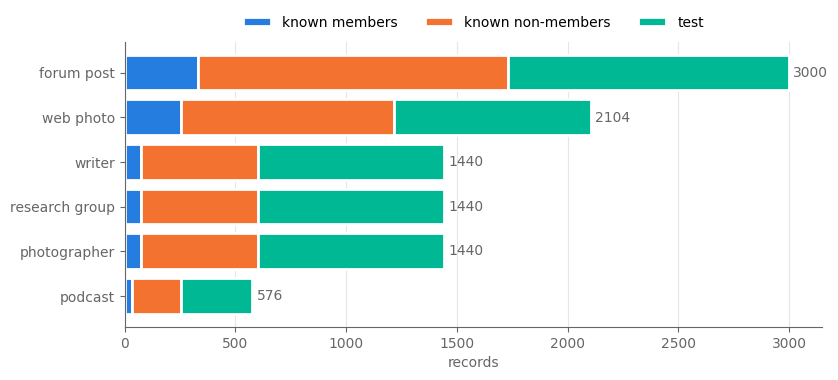

In [3]:
eda.plot_counts(d);

**Conclusion:**

- The data has six source types. Forum posts and web photos are single records: each record has its own owner. They are 43% of test.
- Writers, research groups and podcasts are texts. S1 used texts. Photographers and web photos are photos with a caption. S3 used photos.
- Each owner of a set has 14 test records (podcasts: 8). Thus test has more records of the sets than known.

## 2. How many records are members?

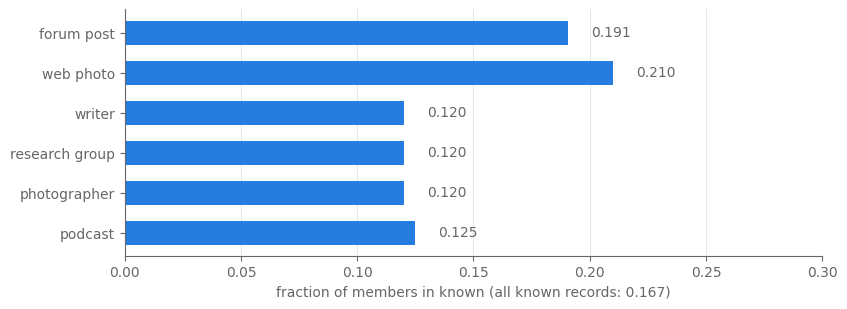

In [4]:
eda.plot_member_rate(d);

**Conclusion:**

- 16.7% of the known records are members.
- Single records have more members: 19% of the forum posts and 21% of the web photos. The sets have 12% to 12.5%.
- The member rate of test is not known. With the same rate, test has approximately 830 members.

## 3. Owners: who is a victim of OpenBUMAS?

An owner is the value of the field `source`. The table counts the owners of the sets for each combination of
known records, test records and known members. Forum posts and web photos are not in the table: each of these records has its own owner.

In [5]:
eda.owner_structure(d)

,source_type,known,test,known_members,owners
0,photographer,8,14,0,40
1,photographer,14,14,0,8
2,photographer,14,14,6,12
3,podcast,5,8,0,26
4,podcast,9,8,0,6
5,podcast,9,8,4,8
6,research group,8,14,0,40
7,research group,14,14,0,8
8,research group,14,14,6,12
9,writer,8,14,0,40


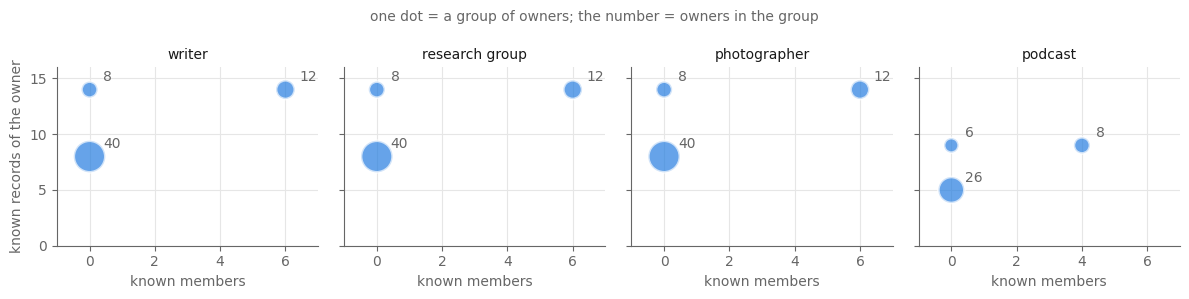

In [6]:
eda.plot_owner_members(d);

**Conclusion:** this is the most important result of the analysis.

- In each set type, 12 of 60 owners have exactly 6 members in 14 known records. Podcasts: 8 of 40 owners have 4 members in 9 known records. We call these owners **victims**.
- All other owners have no known member.
- Thus OpenBUMAS took approximately 43% of the records of a victim, not all records.
- 8 owners in each set type (podcasts: 6) have as many known records as a victim, but no member. Known cannot show if their test records contain members.
- Consequence: the owner prior finds the victims. Inside a victim, an attack on each record must separate the members from the non-members.

## 4. Does the length tell the label?

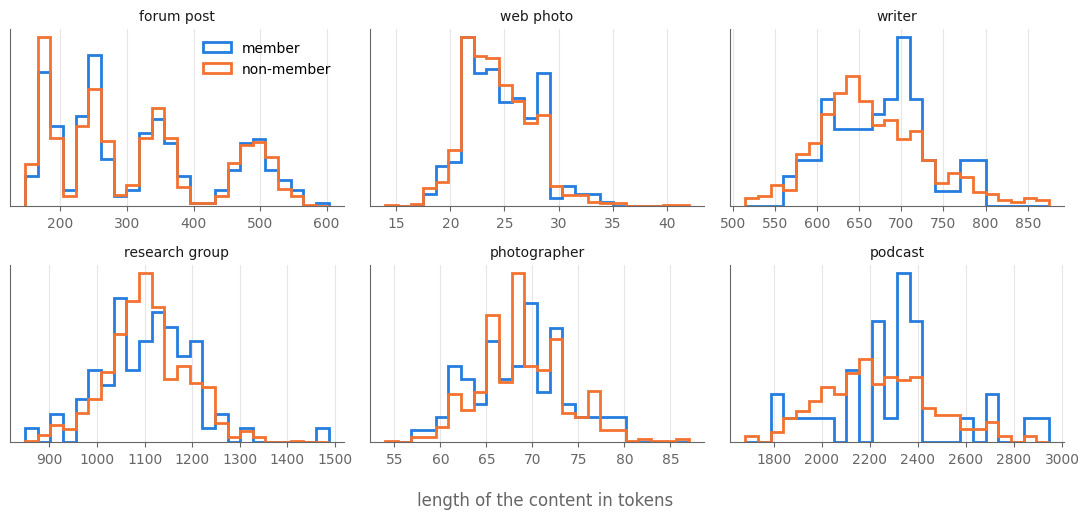

In [7]:
eda.plot_lengths(d);

In [8]:
eda.length_table(d)

,source_type,"median tokens, non-member","median tokens, member",texts above 2048 tokens
0,forum post,279.0,281.0,0.000000
1,web photo,24.0,24.0,NaN
2,writer,657.0,679.0,0.000000
3,research group,1102.0,1111.0,0.000000
4,photographer,69.0,69.0,NaN
5,podcast,2236.0,2316.0,0.765625


**Conclusion:**

- The length does not tell the label. The medians of members and non-members are almost equal. A length score gives a TPR@5%FPR of 0.035 to 0.050 (section 6).
- 77% of the podcasts have more than 2048 tokens. `text_example` cuts a text at 2048 tokens. But S1 joined the texts into pieces of 2048 tokens, so the model saw all tokens.
- Thus an attack must score the full text of a long record, in more than one piece.

## 5. How did the model see a record?

An attack must give the model the same token sequence as the training.
The functions below come from `model/openbumas.py` of the task.

In [9]:
print(eda.input_format(d))

# ---- formatting: every training stage and every attack uses these, so the formats always match ----
def image_block():
    return VISION_START + IMAGE_PAD * N_IMG_TOKENS + VISION_END


def encode_segments(tok, segments, max_len):
    """segments: list of (text, train: bool). Returns ids and labels (-100 where not trained)."""
    ids, labels = [], []
    for text, train in segments:
        t = tok(text, add_special_tokens=False)["input_ids"]
        ids += t
        labels += t if train else [-100] * len(t)
    return ids[:max_len], labels[:max_len]


def caption_example(tok, caption, max_len=256):
    """Image-caption pretraining (S2/S3): image block, then the caption (trained) and EOT."""
    return encode_segments(tok, [(image_block(), False), (caption.strip() + EOT, True)], max_len)


def chat_example(tok, messages, has_image=False, max_len=2048):
    """ChatML; loss only on assistant turns (content + <|im_end|>). If has_image, the image block opens the first user turn."""
    s

In [10]:
display(Markdown(eda.model_card(d)))

# BUMAS-mini (model card)

A small vision-language assistant (about 0.7B parameters), LLaVA-style.

| Part | Component |
|---|---|
| Language model | initialised from **Qwen/Qwen3-0.6B-Base** (public, Apache-2.0), then trained in stages S1 and S3 |
| Vision encoder | **google/siglip2-base-patch16-224** (public, Apache-2.0), frozen in every stage |
| Connector | pixel-shuffle 2x2 + 2-layer MLP, 49 image tokens per image, trained from scratch (S2 and S3) |

Training stages are described in the task README. Data: a mix of public datasets and web data collected by OpenBUMAS.

Loading:
```python
from openbumas import BUMASMini, load_image, text_example, chat_example, caption_example
model = BUMASMini.load("model").cuda().eval()
```
`openbumas.py` contains the exact input formats used in training (plain text, ChatML chats with loss on assistant turns,
image + caption).


In [11]:
eda.model_files(d)

,file,MB
0,model/MODEL_CARD.md,0.0
1,model/connector.pt,16.8
2,model/llm/chat_template.jinja,0.0
3,model/llm/config.json,0.0
4,model/llm/generation_config.json,0.0
5,model/llm/model.safetensors,1192.1
6,model/llm/tokenizer.json,11.4
7,model/llm/tokenizer_config.json,0.0
8,model/openbumas.json,0.0
9,model/openbumas.py,0.0


**Conclusion:**

- A text is `text.strip()` + `<|endoftext|>`. The loss uses all its tokens.
- A photo is the image block (49 image tokens between `<|vision_start|>` and `<|vision_end|>`), then `caption.strip()` + `<|endoftext|>`. The loss uses only the caption tokens.
- An attack must give the model the same sequences. Thus it uses `text_example` and `caption_example` from `openbumas.py`.
- The model card also names chats (ChatML, loss on the assistant turns). The task text has no chat stage, and no record is a chat. Thus we do not use this format.

## 6. Validation method and scores without the model

We use `known.jsonl` as the validation set. `src/validation.py` splits it into folds that copy the relation between known and test:

- Each set owner has records in known and in test. Thus the split is inside each owner, and each fold sees each owner.
  A split by owner (GroupKFold) is not correct here: it tests new owners, and test has no new set owners.
- Single records (forum posts, web photos) are split inside their source type.
- Both splits keep the member rate.

The method uses 2 folds and 5 seeds. A score function gets the `fit` part (with labels) and gives scores for the `evaluate` part.
The metric is the server function on all records of one fold together. The tables show the mean and the standard deviation over the 10 folds.

Limits of the method:

- The `fit` part has only half of the known records of an owner. For test, we use all known records. Thus the owner prior is a little weaker in the validation than for test.
- One fold has 2500 records, test has 5000. Thus the score of one fold has more noise than the score on test.

The scores below do not use the model. An attack must be better than them.

In [12]:
rng = np.random.default_rng(0)
baselines = {
    "random": lambda fit, ev: rng.random(len(ev)),
    "length (longer = member)": lambda fit, ev: ev["length"],
    "length (shorter = member)": lambda fit, ev: -ev["length"],
    "owner prior": eda.owner_prior,
    # Records with the same score go above the threshold together. A random order inside a tie shows the effect.
    "owner prior + random order in a tie": lambda fit, ev: eda.owner_prior(fit, ev) + 1e-6 * rng.random(len(ev)),
}
results = pd.concat([cross_validate(d.known, fn).assign(score=name) for name, fn in baselines.items()])
table = results.groupby(["score", "records"], sort=False)[["TPR@5%FPR", "AUC"]].agg(["mean", "std"]).round(3)
table.loc[(slice(None), "all"), :]

TPR@5%FPR           AUC       
                                                 mean    std   mean    std
score                               records                               
random                              all         0.049  0.013  0.499  0.010
length (longer = member)            all         0.035  0.001  0.451  0.004
length (shorter = member)           all         0.050  0.005  0.549  0.004
owner prior                         all         0.019  0.006  0.740  0.000
owner prior + random order in a tie all         0.180  0.014  0.739  0.004

In [13]:
table

TPR@5%FPR           AUC       
                                                        mean    std   mean    std
score                               records                                      
random                              all                0.049  0.013  0.499  0.010
                                    forum post         0.053  0.008  0.505  0.024
                                    photographer       0.042  0.033  0.514  0.052
                                    podcast            0.062  0.083  0.522  0.101
                                    research group     0.053  0.036  0.486  0.049
                                    web photo          0.046  0.022  0.498  0.026
                                    writer             0.056  0.029  0.470  0.022
length (longer = member)            all                0.035  0.001  0.451  0.004
                                    forum post         0.055  0.018  0.511  0.015
                                    photographer       0.053  0.024  0.477  0.022
                                    podcast            0.106  0.042  0.560  0.035
                                    research group     0.050  0.039  0.503  0.044
                                    web photo          0.050  0.008  0.520  0.020
                                    writer             0.039  0.044  0.554  0.045
length (shorter = member)           all                0.050  0.005  0.549  0.004
                                    forum post         0.036  0.015  0.489  0.015
                                    photographer       0.103  0.037  0.523  0.022
                                    podcast            0.081  0.042  0.440  0.035
                                    research group     0.053  0.020  0.497  0.044
                                    web photo          0.041  0.020  0.480  0.020
                                    writer             0.028  0.023  0.446  0.045
owner prior                         all                0.019  0.006  0.740  0.000
                                    forum post         0.000  0.000  0.500  0.000
                                    photographer       0.000  0.000  0.909  0.000
                                    podcast            0.000  0.000  0.902  0.005
                                    research group     0.000  0.000  0.909  0.000
                                    web photo          0.000  0.000  0.500  0.000
                                    writer             0.000  0.000  0.909  0.000
owner prior + random order in a tie all                0.180  0.014  0.739  0.004
                                    forum post         0.045  0.020  0.494  0.028
                                    photographer       0.258  0.101  0.908  0.012
                                    podcast            0.288  0.094  0.907  0.009
                                    research group     0.272  0.103  0.905  0.009
                                    web photo          0.053  0.021  0.496  0.025
                                    writer             0.328  0.093  0.910  0.010

**Conclusion:**

- Random scores give 0.049. This is the expected value, so the folds and the metric are correct.
- The length gives no signal (0.035 and 0.050).
- The owner prior has an AUC of 0.74, but a TPR@5%FPR of only 0.019. The cause is ties: all records of the victims get the same high score.
  The server puts a tie above the threshold together, and this group has more than 5% of the non-members.
- With a random order inside a tie, the owner prior gives 0.18 (std 0.014). Inside one set type, it gives 0.26 to 0.33.
- Consequence: the prior alone is not sufficient. A good score uses the prior to find the victims and an attack on each record to order the records inside a victim.
- Forum posts and web photos (43% of test) get no help from the prior. Only an attack on each record can find their members.

## 7. Examples of texts and photos

The start of one member and one non-member text of each source type, from known.

In [14]:
eda.text_examples(d)

Four member photos and four non-member photos of each photo source type, with their captions.


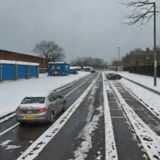
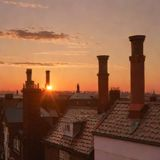
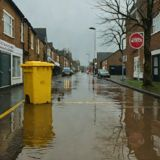
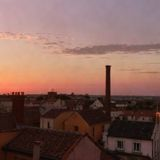
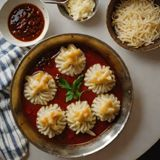
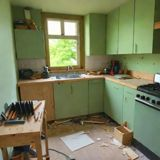
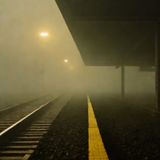
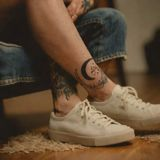
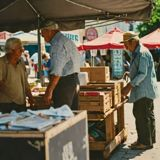
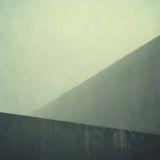
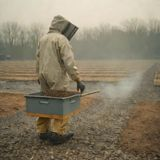
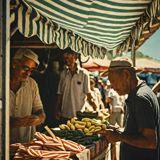
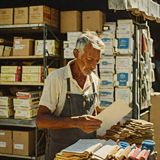
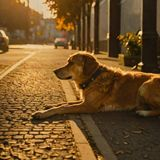
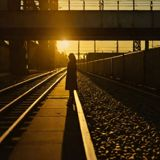
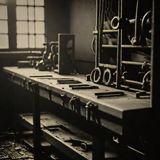

In [15]:
eda.photo_examples(d)

## 8. Checks: photos, duplicates, titles

In [16]:
eda.photo_checks(d)

,check,value
0,photo records,3544
1,records without an image file,0
2,records that share an image file,0
3,most common image size,384 x 384 (100%)


In [17]:
eda.duplicates(d)

,group,split,source_type,source,member,title
31,0,known,web photo,@jonáš_07d6,0.0,None
4233,0,known,web photo,@jaga_5029,0.0,None
8826,0,test,web photo,@aurelia_c409,NaN,None
522,1,known,web photo,@ignacia_9f6f,0.0,None
3762,1,known,web photo,@matej_0f9d,0.0,None
527,2,known,web photo,@whitney_465e,0.0,None
2999,2,known,web photo,@elon_0618,0.0,None
3864,2,known,web photo,@ljubica_b4dc,0.0,None
6209,2,test,web photo,@lucky_cd07,NaN,None
9183,2,test,web photo,@ella_debb,NaN,None


In [18]:
eda.title_at_start(d)

,source_type,fraction of texts that start with the title
0,forum post,0.000000
1,podcast,0.000000
2,research group,0.796528
3,writer,0.504861


**Conclusion:**

- All 3544 photos have an image file, and no two records share an image file. All photos are 384 x 384. The model resizes them to 224 x 224.
- 39 web photo records have the same caption as a different record, but a different photo. Some of these groups have members and non-members. Thus for these records, only the photo can separate the labels.
- 80% of the research group texts and 50% of the writer texts start with their title. Thus the title is often a part of the text that the model saw.

## 9. Conclusions and next steps

Conclusions:

1. **Victims.** 20% of the set owners have members in known, approximately 43% of their records. All other set owners have no known member.
2. **The prior is not sufficient.** It finds the victims, but its ties stop it at the 5% FPR limit. With a random order inside a tie, it gives 0.18.
3. **Single records are 43% of test.** Forum posts and web photos need a strong attack on each record.
4. **No easy signal.** The length does not tell the label.
5. **Exact input format.** An attack uses `text_example` and `caption_example` of `openbumas.py`, and the full text of a long record.
6. **Validation.** `src/validation.py` gives the score of a method on known, with its noise. We make decisions with it, not with the public leaderboard.

Next steps (each approach on its own branch from `pro3`):

1. A GPU job: run BUMAS-mini and the reference model Qwen3-0.6B-Base on all 10 000 records. Keep the log-probability of each token.
2. Compare the attacks on known with `src/validation.py`: LOSS, the reference ratio, Min-K%++ and zlib, separately for texts and photos.
3. Combine the owner prior with the attack scores, and aggregate the scores of the records of each owner.